# Customer Churn Prediction

The objective of this project is to predict customer churn and identify
the factors that are associated with customers leaving the service.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("churn-bigml-20.csv")

In [2]:
df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,LA,117,408,No,No,0,184.5,97,31.37,351.6,80,29.89,215.8,90,9.71,8.7,4,2.35,1,False
1,IN,65,415,No,No,0,129.1,137,21.95,228.5,83,19.42,208.8,111,9.40,12.7,6,3.43,4,True
2,NY,161,415,No,No,0,332.9,67,56.59,317.8,97,27.01,160.6,128,7.23,5.4,9,1.46,4,True
3,SC,111,415,No,No,0,110.4,103,18.77,137.3,102,11.67,189.6,105,8.53,7.7,6,2.08,2,False
4,HI,49,510,No,No,0,119.3,117,20.28,215.1,109,18.28,178.7,90,8.04,11.1,1,3.00,1,False


In [3]:
print(f"Dataset contains {df.shape[0]} rows and {df.shape[1]} columns.")

Dataset contains 667 rows and 20 columns.


In [4]:
# replace spaces with underscores
df.columns = df.columns.str.replace(' ', '_')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 667 entries, 0 to 666
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   667 non-null    object 
 1   Account_length          667 non-null    int64  
 2   Area_code               667 non-null    int64  
 3   International_plan      667 non-null    object 
 4   Voice_mail_plan         667 non-null    object 
 5   Number_vmail_messages   667 non-null    int64  
 6   Total_day_minutes       667 non-null    float64
 7   Total_day_calls         667 non-null    int64  
 8   Total_day_charge        667 non-null    float64
 9   Total_eve_minutes       667 non-null    float64
 10  Total_eve_calls         667 non-null    int64  
 11  Total_eve_charge        667 non-null    float64
 12  Total_night_minutes     667 non-null    float64
 13  Total_night_calls       667 non-null    int64  
 14  Total_night_charge      667 non-null    fl

## Checking the Data for any Unusual Values

In [6]:
for col in df.columns:
  print(f"{col} unique values: {df[col].unique()}\n")

State unique values: ['LA' 'IN' 'NY' 'SC' 'HI' 'AK' 'MI' 'ID' 'VA' 'WI' 'MN' 'VT' 'MT' 'MA'
 'KY' 'CO' 'AZ' 'CA' 'WA' 'NE' 'OH' 'MO' 'AL' 'NH' 'NM' 'OR' 'TX' 'MS'
 'WY' 'FL' 'KS' 'NC' 'SD' 'OK' 'CT' 'RI' 'DE' 'UT' 'NV' 'DC' 'ME' 'IL'
 'NJ' 'MD' 'WV' 'PA' 'ND' 'AR' 'TN' 'IA' 'GA']

Account_length unique values: [117  65 161 111  49  36 119  10  68  74  85  46 128 155  73  77 108  95
 141  63  97  75 127 121   6  32  64  25  93 208 122  99  45 139 215  94
  86 106  92  78  83 144 143  81 145  89 199  96 124 148 135  87  54  35
  84 112 129 140  70  79  91 149  60 115 102  55 126  52  67 165 150  26
  69 157  80  44 101  82  39  30 105 166 172  88 153 109  27   3  43 116
 107 123 110 176  13 156 158 103 151  90  33 167  38 100 136 120 104   1
  76 132 114  48  59  50  12 131 217 134  53  72  98 118 130 159  37  29
 113 163  56  51  66 193   7  71  31 190 170 125 232 182 197  57 137  21
 191  16  34 146 138  62 201 133 162 195 177  41  61 152 175 160  19 142
 189 169  15 180 183  58 196 14

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Account_length,667.0,102.841079,40.819480,1.00,76.00,102.00,128.000,232.00
Area_code,667.0,436.157421,41.783305,408.00,408.00,415.00,415.000,510.00
Number_vmail_messages,667.0,8.407796,13.994480,0.00,0.00,0.00,20.000,51.00
Total_day_minutes,667.0,180.948126,55.508628,25.90,146.25,178.30,220.700,334.30
Total_day_calls,667.0,100.937031,20.396790,30.00,87.50,101.00,115.000,165.00
Total_day_charge,667.0,30.761769,9.436463,4.40,24.86,30.31,37.520,56.83
Total_eve_minutes,667.0,203.355322,49.719268,48.10,171.05,203.70,236.450,361.80
Total_eve_calls,667.0,100.476762,18.948262,37.00,88.00,101.00,113.000,168.00
Total_eve_charge,667.0,17.285262,4.226160,4.09,14.54,17.31,20.095,30.75
Total_night_minutes,667.0,199.685307,49.759931,23.20,167.95,201.60,231.500,367.70


In [9]:
df.sample()

,State,Account_length,Area_code,International_plan,Voice_mail_plan,Number_vmail_messages,Total_day_minutes,Total_day_calls,Total_day_charge,Total_eve_minutes,Total_eve_calls,Total_eve_charge,Total_night_minutes,Total_night_calls,Total_night_charge,Total_intl_minutes,Total_intl_calls,Total_intl_charge,Customer_service_calls,Churn
31,NM,25,415,No,No,0,119.3,87,20.28,211.5,101,17.98,268.9,86,12.1,10.5,4,2.84,3,False


## Removing Irrelevant Columns

In [13]:
df.groupby(['Area_code'])['Churn'].mean()

Area_code
408    0.165680
415    0.121662
510    0.161491
Name: Churn, dtype: float64

##### The churn rate is fairly similar across all three area codes, ranging from around 12% to 17%. Therefore, area code does not appear to have a strong impact on churn, so we can drop this column.

In [14]:
df.drop(columns=['Area_code'], inplace=True)

In [16]:
mcc = df.drop(columns=[
    'State',
    'Account_length',
    'International_plan',
    'Voice_mail_plan',
    'Number_vmail_messages',
    'Customer_service_calls',
    'Churn'
])

In [17]:
mcc.corr()

,Total_day_minutes,Total_day_calls,Total_day_charge,Total_eve_minutes,Total_eve_calls,Total_eve_charge,Total_night_minutes,Total_night_calls,Total_night_charge,Total_intl_minutes,Total_intl_calls,Total_intl_charge
Total_day_minutes,1.000000,-0.032306,1.000000,0.017987,0.043219,0.017945,-0.031600,0.052761,-0.031603,-0.006725,0.016597,-0.006841
Total_day_calls,-0.032306,1.000000,-0.032319,-0.004688,0.005851,-0.004664,0.079536,-0.030074,0.079529,-0.015319,-0.005155,-0.015201
Total_day_charge,1.000000,-0.032319,1.000000,0.017983,0.043231,0.017941,-0.031613,0.052748,-0.031616,-0.006720,0.016582,-0.006836
Total_eve_minutes,0.017987,-0.004688,0.017983,1.000000,-0.029077,1.000000,-0.007705,0.001938,-0.007603,-0.027855,0.002929,-0.027887
Total_eve_calls,0.043219,0.005851,0.043231,-0.029077,1.000000,-0.029089,-0.009856,0.036068,-0.009833,-0.001050,0.074829,-0.001152
Total_eve_charge,0.017945,-0.004664,0.017941,1.000000,-0.029089,1.000000,-0.007691,0.001939,-0.007589,-0.027863,0.002894,-0.027895
Total_night_minutes,-0.031600,0.079536,-0.031613,-0.007705,-0.009856,-0.007691,1.000000,0.005209,0.999999,-0.041969,-0.057212,-0.042221
Total_night_calls,0.052761,-0.030074,0.052748,0.001938,0.036068,0.001939,0.005209,1.000000,0.005195,0.024038,-0.072354,0.023863
Total_night_charge,-0.031603,0.079529,-0.031616,-0.007603,-0.009833,-0.007589,0.999999,0.005195,1.000000,-0.041969,-0.057129,-0.042220
Total_intl_minutes,-0.006725,-0.015319,-0.006720,-0.027855,-0.001050,-0.027863,-0.041969,0.024038,-0.041969,1.000000,0.012600,0.999993


<Axes: >

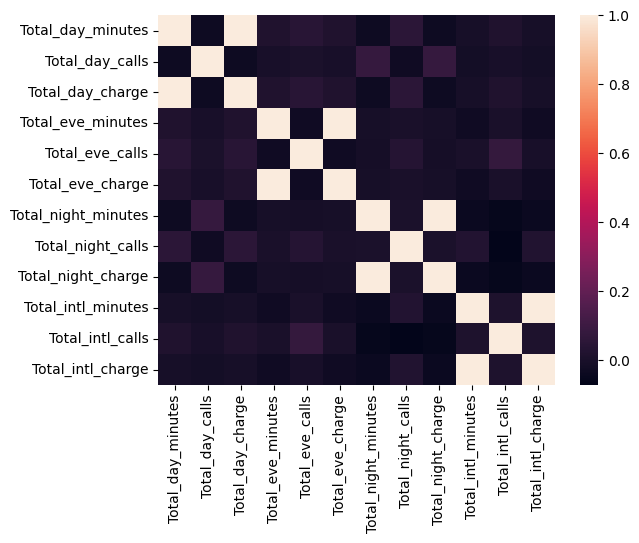

In [18]:
import seaborn as sns
sns.heatmap(mcc.corr())

##### The minutes and charges are highly correlated, so I will keep only the useful ones later. I will also combine the day, evening and night usage into a single overall usage measure.

In [22]:
df['International_plan'] = df['International_plan'].apply(lambda x: 1 if x == 'Yes' else 0)
df['Voice_mail_plan'] = df['Voice_mail_plan'].apply(lambda x: 1 if x == 'Yes' else 0)

In [23]:
df.head()

,State,Account_length,International_plan,Voice_mail_plan,Number_vmail_messages,Total_day_minutes,Total_day_calls,Total_day_charge,Total_eve_minutes,Total_eve_calls,Total_eve_charge,Total_night_minutes,Total_night_calls,Total_night_charge,Total_intl_minutes,Total_intl_calls,Total_intl_charge,Customer_service_calls,Churn
0,LA,117,0,0,0,184.5,97,31.37,351.6,80,29.89,215.8,90,9.71,8.7,4,2.35,1,False
1,IN,65,0,0,0,129.1,137,21.95,228.5,83,19.42,208.8,111,9.40,12.7,6,3.43,4,True
2,NY,161,0,0,0,332.9,67,56.59,317.8,97,27.01,160.6,128,7.23,5.4,9,1.46,4,True
3,SC,111,0,0,0,110.4,103,18.77,137.3,102,11.67,189.6,105,8.53,7.7,6,2.08,2,False
4,HI,49,0,0,0,119.3,117,20.28,215.1,109,18.28,178.7,90,8.04,11.1,1,3.00,1,False


### Now we arae preparing for the modeling

In [25]:
x = df.drop(columns=['Churn'])
y = df['Churn']

In [26]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [27]:
from sklearn.preprocessing import OneHotEncoder

In [29]:
# instantiating ohe object
ohe = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

# fitting ohe on small train data
ohe.fit(x_train[['State']])

# accessing the column names of the states
col_names = ohe.categories_[0]

# making a df with encoded states
state_encoded = pd.DataFrame(
    ohe.transform(x_train[['State']]),
    index=x_train.index,
    columns=col_names
)

# combining the two dfs and dropping State
x_train = pd.concat(
    [x_train.drop('State', axis=1), state_encoded],
    axis=1
)

## Decision Tree Classifier

In [31]:
!pip install imbalanced-learn


   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import KFold
from sklearn.metrics import recall_score, confusion_matrix

In [33]:
def scale_balance_model(
    X_train,
    y_train,
    model,
    scaler=StandardScaler(),
    balance=SMOTE(random_state=42)
):
    
    # creating kfold cross validation object
    kf = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    # creating list to add recall scores
    validation_recall = []

    for train_ind, val_ind in kf.split(X_train, y_train):

        # split into training and validation data
        X_t = X_train.iloc[train_ind]
        y_t = y_train.iloc[train_ind]

        X_val = X_train.iloc[val_ind]
        y_val = y_train.iloc[val_ind]

        # fit scaler on training data and transform both sets
        X_t_sc = scaler.fit_transform(X_t)
        X_val_sc = scaler.transform(X_val)

        # balance the training data using SMOTE
        X_t_resampled, y_t_resampled = balance.fit_resample(
            X_t_sc,
            y_t
        )

        # fit the model
        model.fit(
            X_t_resampled,
            y_t_resampled
        )

        # calculate recall on validation data
        validation_recall.append(
            recall_score(
                y_val,
                model.predict(X_val_sc)
            )
        )

    print(f"Validation recall scores: {validation_recall}")
    print(f"Mean validation recall score: {np.mean(validation_recall):.3f}")

    print("\nConfusion matrix from the last validation fold:")
    print(
        confusion_matrix(
            y_val,
            model.predict(X_val_sc)
        )
    )

In [34]:
model = DecisionTreeClassifier(max_depth = 5, random_state = 42)
scale_balance_model(x_train, y_train, model)

Validation recall scores: [np.float64(0.42857142857142855), np.float64(0.38461538461538464), np.float64(0.8), np.float64(0.5625), np.float64(0.4)]
Mean validation recall score: 0.515

Confusion matrix from the last validation fold:
[[81 10]
 [ 9  6]]


In [35]:
import matplotlib.pyplot as plt
%matplotlib inline

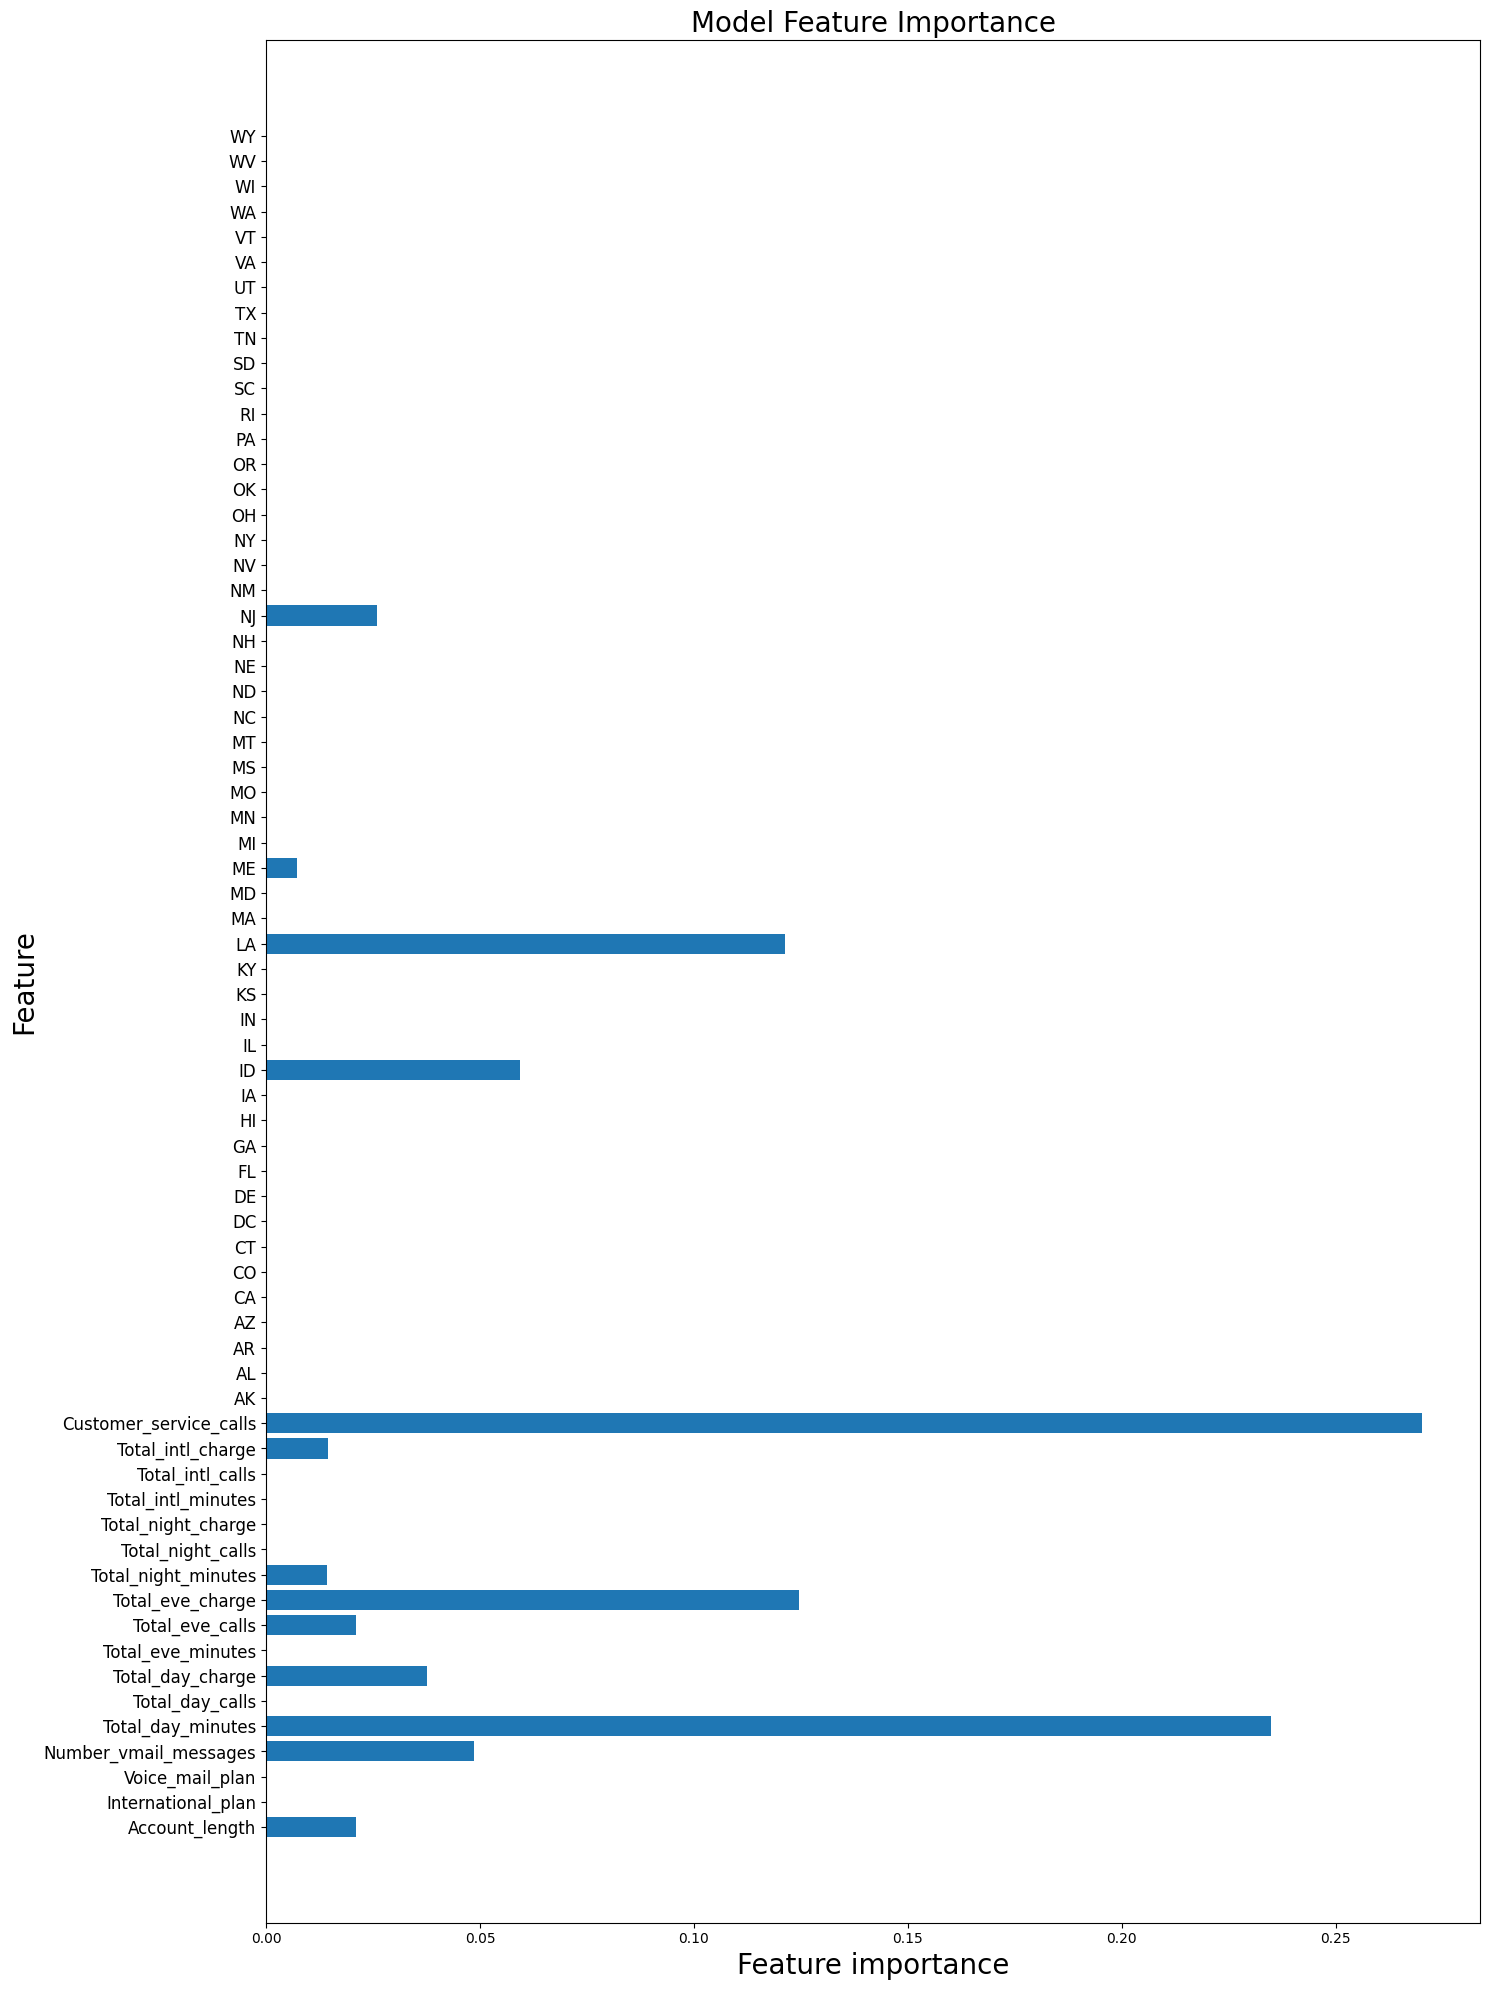

In [36]:
n_features = x_train.shape[1]
plt.figure(figsize=(15, 20))
plt.barh(range(n_features), model.feature_importances_);
plt.yticks(np.arange(n_features), x_train.columns.values, fontsize = 12)
plt.xlabel('Feature importance', fontsize = 20)
plt.ylabel('Feature', fontsize = 20)
plt.title('Model Feature Importance', fontsize = 20)
plt.tight_layout()
plt.savefig('./model_feat_import.png')

From the feature importance graph, we can see that these three features stand out compared to the others:

1. `International_plan`
2. `Total_day_charge`
3. `Customer_service_calls`

So, these variables seem to play a bigger role in predicting customer churn.

#### Checking the correlation of all the features with churn to see whether these three features actually have a strong relationship with churn.

In [39]:
# correlations with churn
df.corr(numeric_only=True)['Churn'].sort_values(ascending=False)

Churn                     1.000000
Total_day_minutes         0.242781
Total_day_charge          0.242777
Customer_service_calls    0.233259
Total_eve_charge          0.175616
Total_eve_minutes         0.175614
Total_eve_calls           0.055669
Total_night_charge        0.042958
Total_night_minutes       0.042930
Total_day_calls           0.019360
Total_intl_calls          0.015331
Account_length            0.012315
Total_intl_charge        -0.003681
Total_intl_minutes       -0.003740
Total_night_calls        -0.017626
Number_vmail_messages    -0.102381
International_plan             NaN
Voice_mail_plan                NaN
Name: Churn, dtype: float64

## Performing more EDA on these features

### 1. International plan

In [46]:
df = pd.read_csv("churn-bigml-20.csv")
df.columns = df.columns.str.replace(' ', '_')
df['International_plan'] = df['International_plan'].apply(lambda x: 1 if x == 'Yes' else 0)
df['Voice_mail_plan'] = df['Voice_mail_plan'].apply(lambda x: 1 if x == 'Yes' else 0)

In [47]:
df['International_plan'].value_counts()

International_plan
0    614
1     53
Name: count, dtype: int64

In [49]:
int_plan_churn = pd.DataFrame(df.groupby('International_plan')['Churn'].mean())
int_plan_churn

,Churn
International_plan,
0,0.123779
1,0.358491


C:\Users\prabh\AppData\Local\Temp\ipykernel_12584\4021570095.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['No International Plan', 'Has International Plan'])


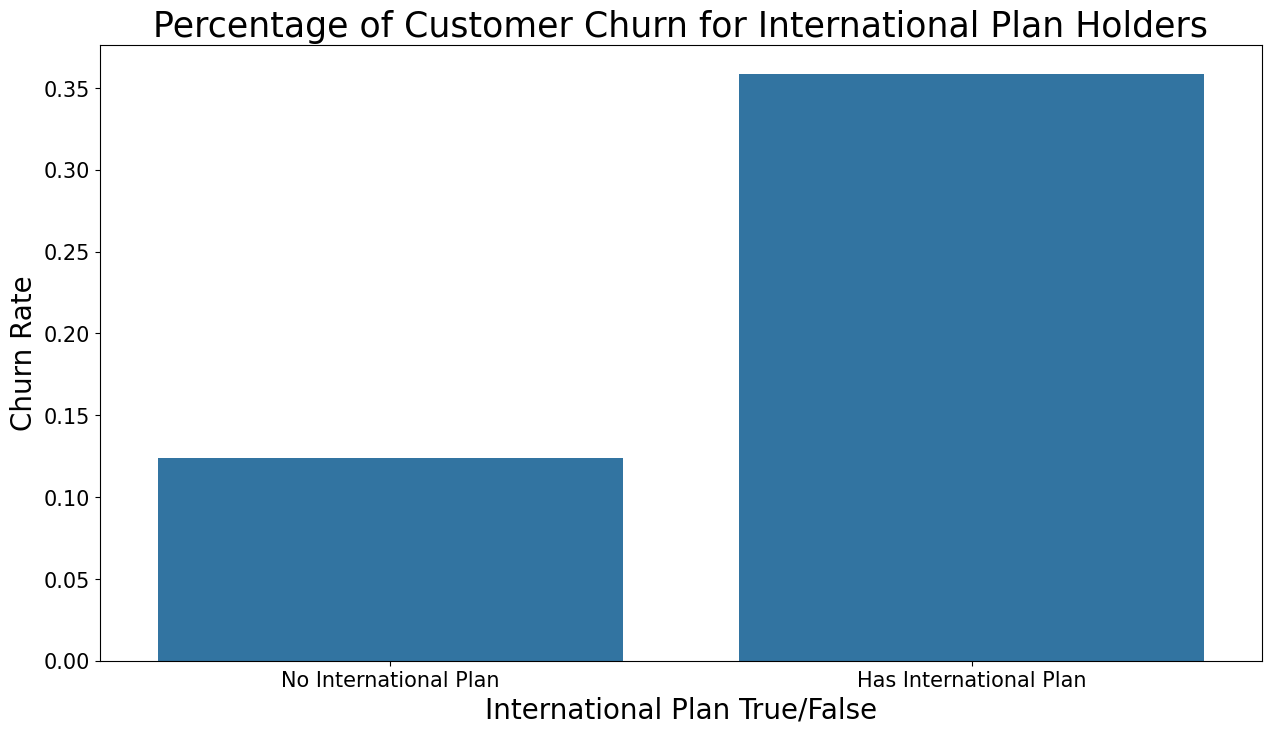

In [51]:
# plot
fig, ax = plt.subplots(figsize=(15,8))
sns.barplot(x=[0,1], y='Churn', data=int_plan_churn, ax=ax)
plt.title('Percentage of Customer Churn for International Plan Holders', fontsize=25)
ax.tick_params(axis='both', labelsize=15)
plt.xlabel('International Plan True/False', fontsize=20)
plt.ylabel('Churn Rate', fontsize=20)
ax.set_xticklabels(['No International Plan', 'Has International Plan'])
plt.savefig('./int_plan_churn.png')

Around 36% of customers with an international plan churned, so the international plan appears to be an important factor related to churn.

### 2. Customer Service Calls

In [52]:
csc = pd.DataFrame(df.groupby(['Customer_service_calls'])['Churn'].mean())
csc

,Churn
Customer_service_calls,
0,0.091549
1,0.097458
2,0.165563
3,0.086420
4,0.363636
5,0.647059
6,0.800000
7,0.000000
8,0.000000


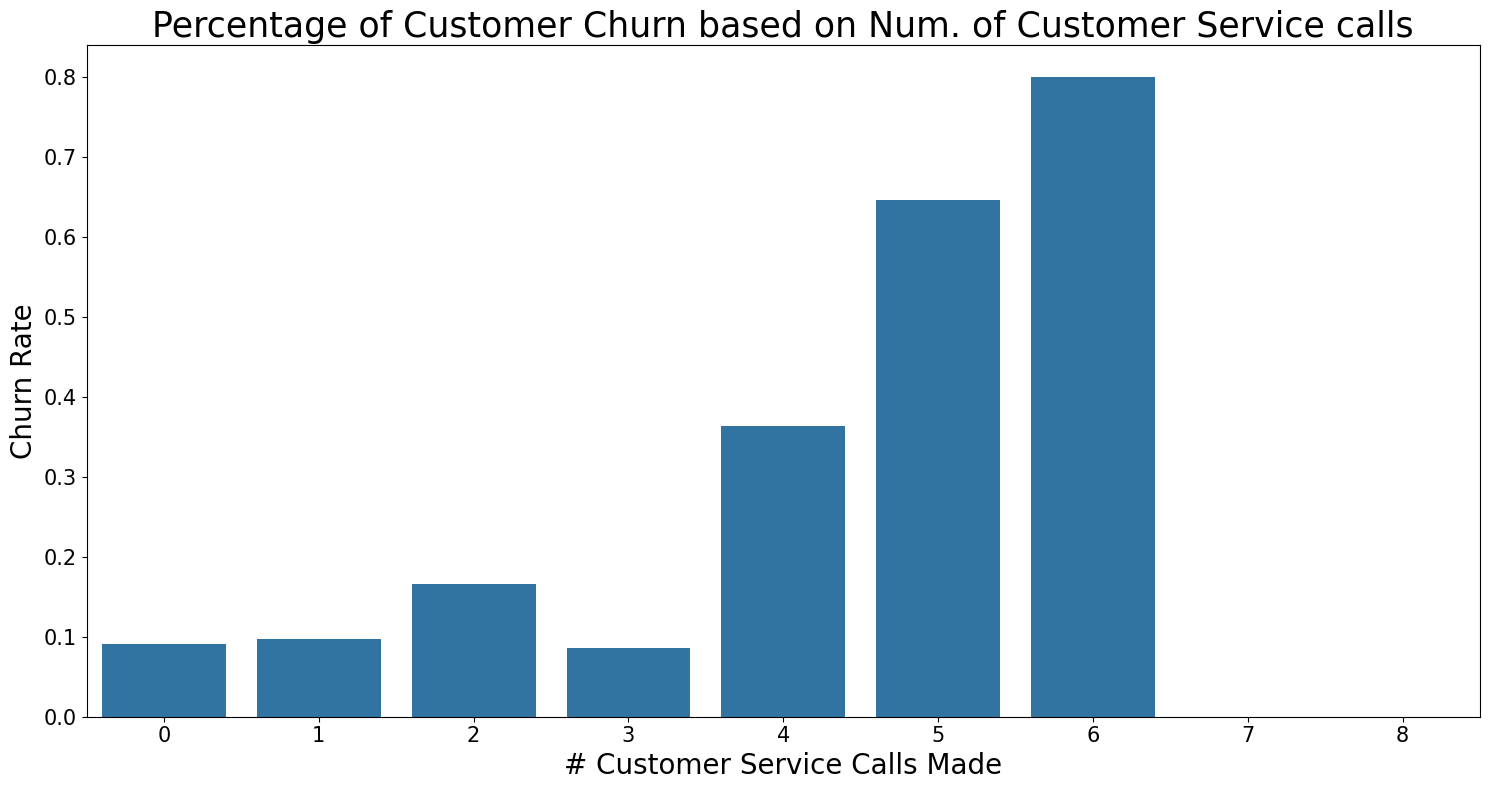

In [54]:
fig, ax = plt.subplots(figsize=(15,8))
sns.barplot(x=[0,1,2,3,4,5,6,7,8], y='Churn', data=csc, ax=ax)
plt.title('Percentage of Customer Churn based on Num. of Customer Service calls', fontsize=25)
ax.tick_params(axis='both', labelsize=15)
plt.xlabel('# Customer Service Calls Made', fontsize=20)
plt.ylabel('Churn Rate', fontsize=20)
plt.tight_layout()
plt.savefig('./cust_serv_call_churn.png')

There is a clear increase in churn for customers making 4 or more customer service calls. The churn rate reaches around 80% for customers who make 6 calls.

### 3. Total Day Charge

C:\Users\prabh\AppData\Local\Temp\ipykernel_12584\2417747037.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df.Total_day_charge, ax=ax)


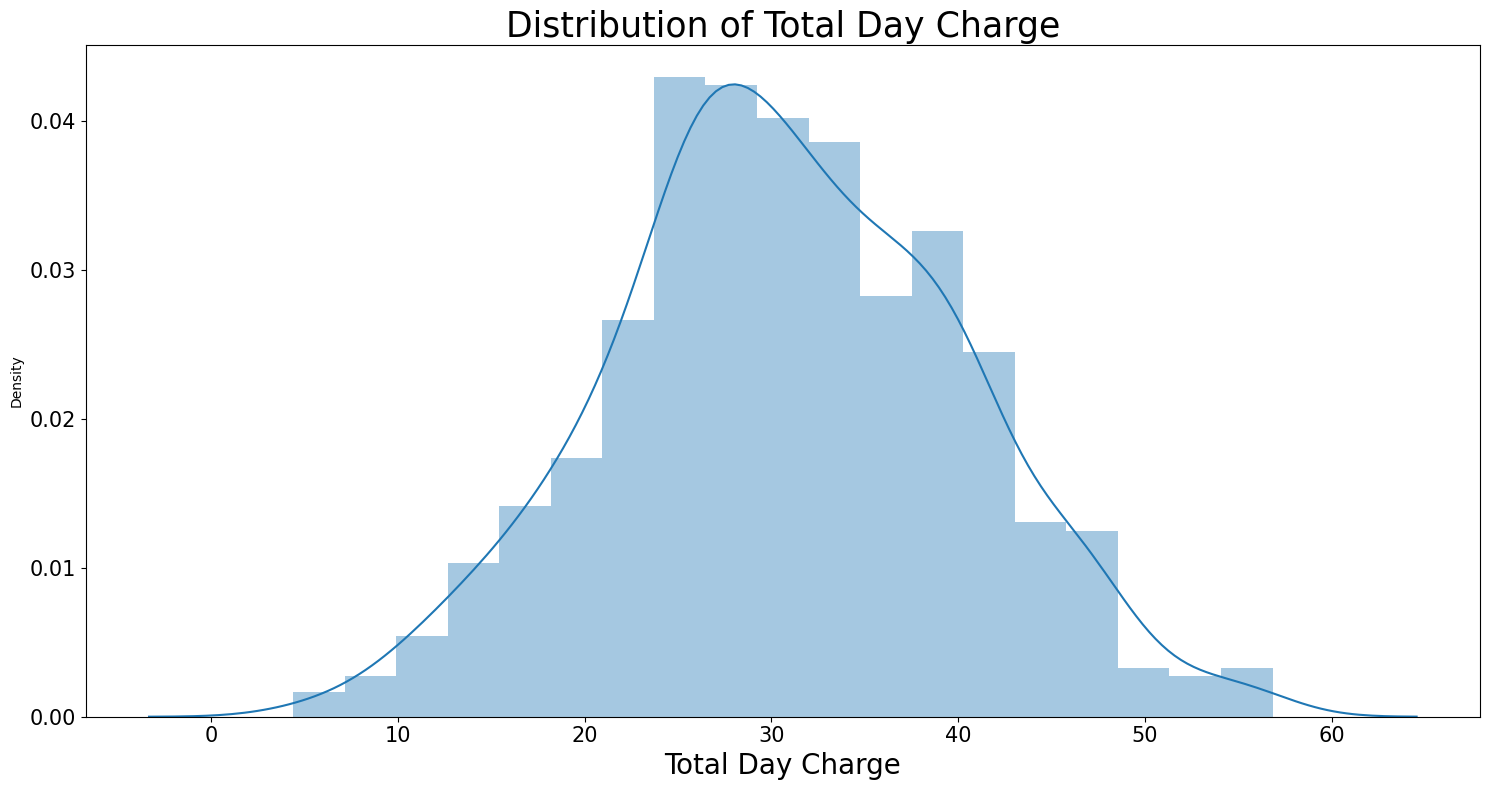

In [55]:
fig, ax = plt.subplots(figsize=(15,8))
plt.title('Distribution of Total Day Charge', fontsize=25)
sns.distplot(df.Total_day_charge, ax=ax)
ax.tick_params(axis='both', labelsize=15)
plt.xlabel('Total Day Charge', fontsize=20)
plt.tight_layout()
plt.savefig('./tot_day_charge_dist.png')

The distribution is roughly normal with a slight right skew. There are no major unusual values or obvious outliers.

In [57]:
tdc = pd.DataFrame(df.groupby(['Total_day_charge'])['Churn'].mean())
tdc

,Churn
Total_day_charge,
4.40,0.0
5.97,0.0
6.95,0.0
7.63,0.0
8.76,0.0
...,...
54.83,1.0
55.20,1.0
55.51,1.0


<Axes: xlabel='Churn', ylabel='Total_day_charge'>

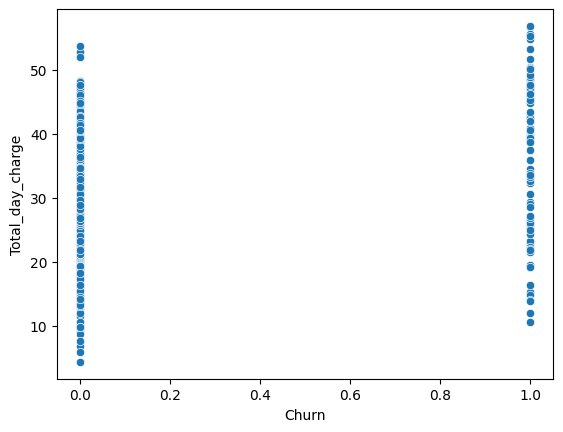

In [59]:
sns.scatterplot(x=df['Churn'], y=df['Total_day_charge'])

Customers with total day charges above roughly $55 show a 100% churn rate in this dataset.

In [60]:
tdc['churn_rate'] = tdc['Churn'] * 100
tdc.drop('Churn', axis=1).iloc[-20:]

,churn_rate
Total_day_charge,
48.13,0.0
48.26,0.0
48.35,100.0
48.86,100.0
49.15,100.0
49.93,100.0
50.15,100.0
50.32,100.0
50.39,100.0


We can see that customers with higher total day charges are more likely to churn. However, the relationship is not completely consistent, as some customers with charges around $52–54 did not churn.

### 4. States

In [61]:
df.groupby('State')['Churn'].mean().sort_values(ascending=False)

State
CA    0.400000
MD    0.300000
CO    0.285714
SC    0.272727
MT    0.266667
OR    0.250000
ID    0.235294
MA    0.230769
NJ    0.222222
OK    0.222222
WA    0.222222
NY    0.200000
MI    0.200000
NV    0.200000
SD    0.181818
IN    0.176471
MS    0.176471
WI    0.176471
RI    0.176471
WV    0.166667
UT    0.166667
NC    0.166667
MO    0.166667
KS    0.166667
ME    0.153846
MN    0.142857
VT    0.125000
KY    0.125000
TX    0.117647
NM    0.111111
HI    0.111111
FL    0.111111
ND    0.111111
DE    0.100000
VA    0.100000
WY    0.090909
IL    0.076923
AL    0.071429
CT    0.066667
LA    0.062500
NE    0.062500
AZ    0.052632
AK    0.000000
IA    0.000000
GA    0.000000
DC    0.000000
AR    0.000000
NH    0.000000
TN    0.000000
OH    0.000000
PA    0.000000
Name: Churn, dtype: float64

We can see that California has the highest churn rate at 40%, followed by Maryland at 30% and Colorado at around 28.6%. Several states have 0% churn in this dataset, but this may also be due to the smaller number of customers from those states.

## Trying Different Models

After building the first model, the next step is to see if we can improve
the recall score. I will compare a few commonly used classification models:

- DecisionTreeClassifier()
- KNeighborsClassifier()
- RandomForestClassifier()
- LogisticRegression()
- GradientBoostingClassifier()

Comparing these models will give us an idea of which one is better suited
for predicting customer churn and which model is worth tuning further.

In [62]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [63]:
def compare_models(X_train, y_train):
    # create kfolds object
    kf = KFold(n_splits = 5, shuffle=True, random_state = 42)

    for train_ind, val_ind in kf.split(X_train, y_train):

        performance = pd.DataFrame(columns=['Train_Recall','Test_Recall','Test_Specificity'])
        mu_performance = pd.DataFrame(columns=['Train_Recall','Test_Recall','Test_Specificity'])

        recall = make_scorer(recall_score)

        X_t, y_t = X_train.iloc[train_ind], y_train.iloc[train_ind]
        X_val, y_val = X_train.iloc[val_ind], y_train.iloc[val_ind]

        # instantiate and fit/transform scaler
        ss = StandardScaler()

        X_t_sc = ss.fit_transform(X_t)
        X_val_sc = ss.transform(X_val)

        # instantiate and fit SMOTE:
        smote = SMOTE(random_state = 42)
        X_t_sc_bal, y_t_bal = smote.fit_resample(X_t_sc, y_t)

        classifiers = [DecisionTreeClassifier(), KNeighborsClassifier(),
                   RandomForestClassifier(n_estimators = 10), LogisticRegression(),
                   GradientBoostingClassifier()]

        for clf in classifiers:
            train_cv = cross_val_score(X=X_t_sc_bal, y=y_t_bal,
                                       estimator=clf, scoring=recall,cv=10) #cv is no. of folds like in KFold we do, estimator is used to fit data

            # Predict
            y_pred = clf.fit(X_t_sc_bal, y_t_bal).predict(X_val_sc)

            conf_matrix = confusion_matrix(y_val,y_pred)

            # Store results
            performance.loc[clf.__class__.__name__+'_default',
                            ['Train_Recall','Test_Recall','Test_Specificity']] = [
                train_cv.mean(), #Train Recall = mean of all scores, run for an estimator cv no. of times
                recall_score(y_val,y_pred), #Test Recall = TP/TP+FN
                conf_matrix[0,0]/conf_matrix[0,:].sum() #Test Specificity = TN/TN+FP
            ]
        mu_performance = pd.concat([mu_performance,performance])
        print(mu_performance, '\n')

In [64]:
compare_models(x_train, y_train)

                                   Train_Recall Test_Recall Test_Specificity
DecisionTreeClassifier_default         0.907432     0.47619         0.883721
KNeighborsClassifier_default           0.959159    0.190476         0.767442
RandomForestClassifier_default         0.923724    0.380952         0.976744
LogisticRegression_default             0.871997    0.428571          0.77907
GradientBoostingClassifier_default      0.93491     0.47619         0.953488 

                                   Train_Recall Test_Recall Test_Specificity
DecisionTreeClassifier_default         0.911111    0.538462          0.87234
KNeighborsClassifier_default           0.936032    0.230769         0.744681
RandomForestClassifier_default         0.874921    0.153846         0.946809
LogisticRegression_default             0.830238    0.461538         0.787234
GradientBoostingClassifier_default        0.925    0.615385         0.904255 

                                   Train_Recall Test_Recall Test_Specifi

From the results above, Gradient Boosting Classifier performs better overall, giving a good balance between test recall and test specificity across the different splits.

## Hyperparameter Tuning

### Model 2:

In [65]:
from sklearn.preprocessing import MinMaxScaler

In [66]:
gbc2 = GradientBoostingClassifier(loss='exponential', learning_rate=0.2, random_state=42)
scale_balance_model(x_train, y_train, gbc2, MinMaxScaler())

Validation recall scores: [np.float64(0.47619047619047616), np.float64(0.6923076923076923), np.float64(0.6666666666666666), np.float64(0.6875), np.float64(0.5333333333333333)]
Mean validation recall score: 0.611

Confusion matrix from the last validation fold:
[[84  7]
 [ 7  8]]


The first model had a mean recall score of around 0.597, while Model 2 gives 0.611. So, the recall has improved slightly with the new parameters.

### Model 3:

In [67]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "loss": ["exponential", "log_loss"],
    "learning_rate": [0.01, 0.05],
    "min_samples_split": [1.0, 2, 5]
}

gbc3 = GradientBoostingClassifier(random_state=42)

search = GridSearchCV(
    gbc3, param_grid, n_jobs=-1, cv=3, scoring="recall"
)

search.fit(x_train, y_train)

print("Best parameters:\n", search.best_params_)

Best parameters:
 {'learning_rate': 0.05, 'loss': 'log_loss', 'min_samples_split': 5}


In [68]:
gbc3 = GradientBoostingClassifier(
    learning_rate=0.05, loss='log_loss',
    min_samples_split=5, random_state=42
)
scale_balance_model(x_train, y_train, gbc3, MinMaxScaler())

Validation recall scores: [np.float64(0.5714285714285714), np.float64(0.5384615384615384), np.float64(0.7333333333333333), np.float64(0.6875), np.float64(0.6666666666666666)]
Mean validation recall score: 0.639

Confusion matrix from the last validation fold:
[[86  5]
 [ 5 10]]


### Model 4:

In [69]:
param_grid = {
    "loss": ["exponential", "log_loss"],
    "learning_rate": [0.01],
    "min_samples_split": [1.0, 2, 5]
}

gbc4 = GradientBoostingClassifier(random_state=42)
search = GridSearchCV(gbc4, param_grid, n_jobs=-1, cv=3, scoring='recall')
search.fit(x_train, y_train)

print("Best parameters:\n", search.best_params_)

Best parameters:
 {'learning_rate': 0.01, 'loss': 'log_loss', 'min_samples_split': 2}


In [70]:
gbc4 = GradientBoostingClassifier(
    loss='log_loss', learning_rate=0.01,
    min_samples_split=2, random_state=42
)
scale_balance_model(x_train, y_train, gbc4, MinMaxScaler())

Validation recall scores: [np.float64(0.6666666666666666), np.float64(0.6923076923076923), np.float64(0.7333333333333333), np.float64(0.6875), np.float64(0.7333333333333333)]
Mean validation recall score: 0.703

Confusion matrix from the last validation fold:
[[84  7]
 [ 4 11]]


### Model 5:

In [72]:
gbc5 = GradientBoostingClassifier(
    loss='log_loss', learning_rate=0.01,
    min_samples_split=2, random_state=42
)
scale_balance_model(x_train, y_train, gbc5, StandardScaler())

Validation recall scores: [np.float64(0.7142857142857143), np.float64(0.6153846153846154), np.float64(0.8666666666666667), np.float64(0.6875), np.float64(0.7333333333333333)]
Mean validation recall score: 0.723

Confusion matrix from the last validation fold:
[[85  6]
 [ 4 11]]


In [73]:
gbc6a = GradientBoostingClassifier(
    loss='log_loss', learning_rate=0.01,
    min_samples_leaf=0.2, min_samples_split=0.2,
    max_depth=3, random_state=42
)
scale_balance_model(x_train, y_train, gbc6a, StandardScaler())

Validation recall scores: [np.float64(0.7619047619047619), np.float64(0.8461538461538461), np.float64(0.9333333333333333), np.float64(0.6875), np.float64(0.6)]
Mean validation recall score: 0.766

Confusion matrix from the last validation fold:
[[66 25]
 [ 6  9]]


In [75]:
gbc7 = GradientBoostingClassifier(
    loss='log_loss', learning_rate=0.01,
    min_samples_leaf=0.1, min_samples_split=2,
    max_depth=3, random_state=42
)
scale_balance_model(x_train, y_train, gbc7, StandardScaler())

Validation recall scores: [np.float64(0.7619047619047619), np.float64(0.7692307692307693), np.float64(0.9333333333333333), np.float64(0.6875), np.float64(0.8)]
Mean validation recall score: 0.790

Confusion matrix from the last validation fold:
[[78 13]
 [ 3 12]]


## Final Test Model using Gradient Boosting

### One Hot Encode Test Data

In [80]:
test_state_encoded = pd.DataFrame(
    ohe.transform(x_test[['State']]),
    index=x_test.index,
    columns=col_names
)

x_test = pd.concat([x_test.drop('State', axis=1), test_state_encoded], axis=1)

In [81]:
ss = StandardScaler()

X_train_ss = ss.fit_transform(x_train)
X_test_ss = ss.transform(x_test)

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_ss, y_train)

final = GradientBoostingClassifier(
    loss='exponential', learning_rate=0.01,
    min_samples_leaf=0.2, min_samples_split=0.2,
    max_depth=3, random_state=42
)

final.fit(X_train_resampled, y_train_resampled)

print(f'Train: {recall_score(y_train, final.predict(X_train_ss))}')
print(f'Test: {recall_score(y_test, final.predict(X_test_ss))}')
print(confusion_matrix(y_test, final.predict(X_test_ss)))

Train: 0.75
Test: 0.8
[[85 34]
 [ 3 12]]


## Result

The final Gradient Boosting model achieved a recall score of 0.80 on the test data.

## Conclusion and Scope of Improvement

The analysis helped identify several factors that are related to customer churn. 
By performing EDA and testing different classification models, Gradient Boosting 
gave the best overall performance among the models considered. The final model 
achieved a recall score of 0.80 on the test data, which means it was able to 
identify a good proportion of customers who were likely to churn.

The analysis also highlighted some areas that could be explored further to better 
understand customer behaviour and improve retention strategies.

1. Understanding the reasons behind frequent customer service calls could help 
   the company identify problems faced by customers and improve its support process.

2. Customers with international plans showed a relatively higher churn rate, so 
   further analysis could help understand their requirements and improve retention 
   efforts for this group.

3. The relationship between higher day charges and customer churn can be studied 
   further to understand whether pricing or usage patterns are influencing 
   customers' decision to leave.

4. States with comparatively higher churn rates could be investigated to identify 
   regional patterns and understand whether there are any location-specific factors 
   affecting customer churn.

Overall, the model can be used as a starting point for identifying customers who 
are more likely to churn. Further feature engineering, model tuning and additional 
customer information could help improve the model's performance in the future.